Ex 1

In [18]:
import numpy as np
from hmmlearn.hmm import CategoricalHMM

def ex1(pi, A, B, obs_seq):
    states = ["C1", "C2", "C3", "C4"]
    obs_symbols = ["R", "G", "B"]
    symbol_to_idx = {s: i for i, s in enumerate(obs_symbols)}
    
    model = CategoricalHMM(n_components=len(states), n_features=len(obs_symbols))
    model.startprob_ = pi
    model.transmat_ = A
    model.emissionprob_ = B

    X = np.array([[symbol_to_idx[s]] for s in obs_seq], dtype=int)

    log_prob, hidden_idx = model.decode(X, algorithm="viterbi")
    decoded_states = [states[i] for i in hidden_idx]

    print("Log probability of best path:", log_prob)
    print("Hidden state indices:", hidden_idx)
    print("Most likely state sequence:", decoded_states)

In [20]:
pi = np.array([0.25, 0.25, 0.25, 0.25])
A = np.array([
    [0.6, 0.4, 0.0, 0.0],
    [0.4, 0.2, 0.4, 0.0],
    [0.0, 0.4, 0.2, 0.4],
    [0.0, 0.0, 0.4, 0.6],
])

B = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3],
])
ex1(pi, A, B, ["R", "G", "B", "B", "R"])

Log probability of best path: -7.921438356864941
Hidden state indices: [0 1 2 3 3]
Most likely state sequence: ['C1', 'C2', 'C3', 'C4', 'C4']


### b)

In [21]:
import numpy as np
from hmmlearn.hmm import CategoricalHMM

pi = np.array([0.25, 0.25, 0.25, 0.25])

A = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
])

B = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

ex1(pi, A, B, ["R", "G", "B", "B", "R"])

Log probability of best path: -7.097857023095054
Hidden state indices: [0 1 2 3 0]
Most likely state sequence: ['C1', 'C2', 'C3', 'C4', 'C1']


3.a)
P(defect) = theta
theta ~ Beta(2, 8)
Din 20 produse 5 sunt defecte

a) Determinati distributia a posteriori, media ei, si reprezentati grafic densitatile a posteriori

Distributia a posteriori: Beta(7, 23)
Media a priori: 0.2000 (20.00%)
Media a posteriori: 0.2333 (23.33%)


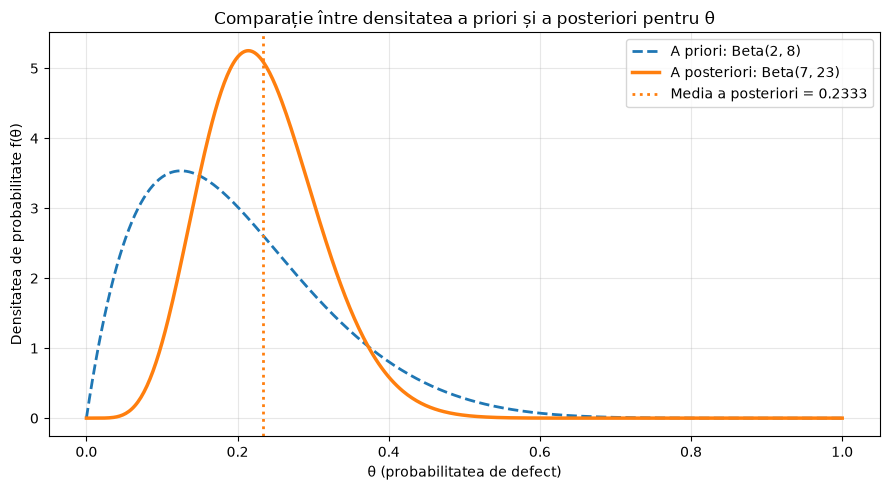

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta

alpha_prior, beta_prior = 2, 8
n = 20
k = 5

alpha_post = alpha_prior + k
beta_post = beta_prior + (n - k)

print(f"Distributia a posteriori: Beta({alpha_post}, {beta_post})")

mean_prior = beta.mean(alpha_prior, beta_prior)
mean_post = beta.mean(alpha_post, beta_post)

print(f"Media a priori: {mean_prior:.4f} ({mean_prior*100:.2f}%)")
print(f"Media a posteriori: {mean_post:.4f} ({mean_post*100:.2f}%)")

theta = np.linspace(0, 1, 500)
pdf_prior = beta.pdf(theta, alpha_prior, beta_prior)
pdf_post = beta.pdf(theta, alpha_post, beta_post)

plt.figure(figsize=(9, 5))
plt.plot(
    theta,
    pdf_prior,
    label=f"A priori: Beta({alpha_prior}, {beta_prior})",
    linestyle="--",
    linewidth=2,
)
plt.plot(
    theta,
    pdf_post,
    label=f"A posteriori: Beta({alpha_post}, {beta_post})",
    linewidth=2.5,
)
plt.axvline(
    mean_post,
    color="C1",
    linestyle=":",
    linewidth=2,
    label=f"Media a posteriori = {mean_post:.4f}",
)

plt.title("Comparație între densitatea a priori și a posteriori pentru θ")
plt.xlabel("θ (probabilitatea de defect)")
plt.ylabel("Densitatea de probabilitate f(θ)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

b) Un al doilea lot independent de primul contine 3 produse defecte din 15. Determinati distributia a posteriori dupa ambele loturi

Distributia a posteriori dupa lotul 1: Beta(7, 23)
Distributia a posteriori dupa ambele loturi: Beta(10, 35)
Noua medie a posteriori: 0.2222 (22.22%)


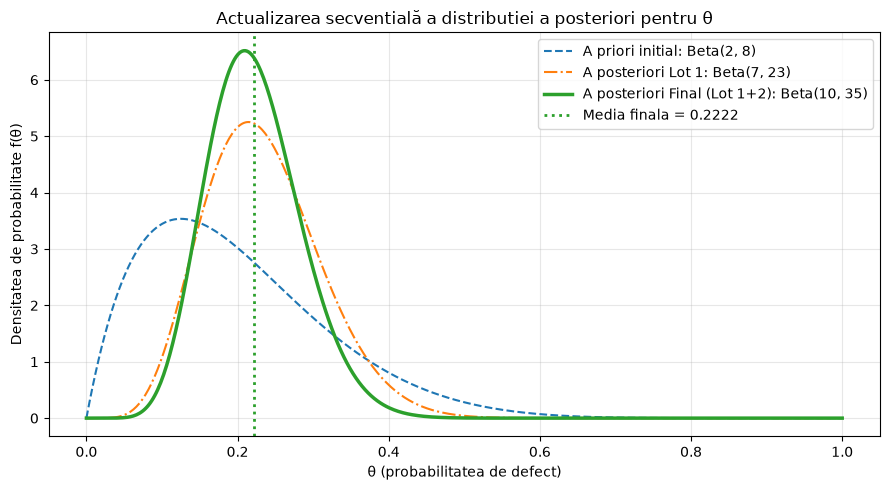

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta

alpha_0, beta_0 = 2, 8

n1, k1 = 20, 5
alpha_1 = alpha_0 + k1
beta_1 = beta_0 + (n1 - k1)

n2, k2 = 15, 3
alpha_2 = alpha_1 + k2
beta_2 = beta_1 + (n2 - k2)

print(f"Distributia a posteriori dupa lotul 1: Beta({alpha_1}, {beta_1})")
print(f"Distributia a posteriori dupa ambele loturi: Beta({alpha_2}, {beta_2})")
print(f"Noua medie a posteriori: {beta.mean(alpha_2, beta_2):.4f} ({beta.mean(alpha_2, beta_2)*100:.2f}%)")

theta = np.linspace(0, 1, 500)

plt.figure(figsize=(9, 5))
plt.plot(theta, beta.pdf(theta, alpha_0, beta_0), "--", label=f"A priori initial: Beta({alpha_0}, {beta_0})")
plt.plot(theta, beta.pdf(theta, alpha_1, beta_1), "-.", label=f"A posteriori Lot 1: Beta({alpha_1}, {beta_1})")
plt.plot(theta, beta.pdf(theta, alpha_2, beta_2), linewidth=2.5, label=f"A posteriori Final (Lot 1+2): Beta({alpha_2}, {beta_2})")

plt.axvline(beta.mean(alpha_2, beta_2), color="C2", linestyle=":", linewidth=2,
            label=f"Media finala = {beta.mean(alpha_2, beta_2):.4f}")

plt.title("Actualizarea secventială a distributiei a posteriori pentru θ")
plt.xlabel("θ (probabilitatea de defect)")
plt.ylabel("Densitatea de probabilitate f(θ)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

c) Determinati distributia a posteriori folosind numai al doilea lot si aceeasi distributie initiala Beta(2,8). Comparati cele doua rezultate de la b) si c) si explicati diferenta

b) Ambele loturi Beta(10, 35):
  Media = 0.2222 | Std = 0.0613 | IC 95% = [0.1147, 0.3530]

c) Doar lotul 2 Beta(5, 20):
  Media = 0.2000 | Std = 0.0784 | IC 95% = [0.0713, 0.3738]



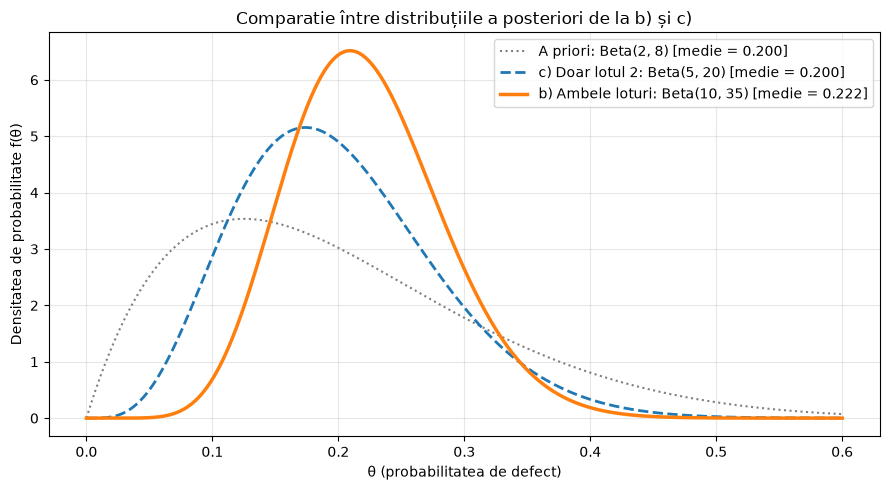

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta

dist_b = beta(10, 35)  # Ambele loturi
dist_c = beta(5, 20)   # Doar al doilea lot
dist_prior = beta(2, 8)

for nume, d in [("b) Ambele loturi Beta(10, 35)", dist_b), ("c) Doar lotul 2 Beta(5, 20)", dist_c)]:
    ci_low, ci_high = d.interval(0.95)
    print(f"{nume}:")
    print(f"  Media = {d.mean():.4f} | Std = {d.std():.4f} | IC 95% = [{ci_low:.4f}, {ci_high:.4f}]\n")

theta = np.linspace(0, 0.6, 500)

plt.figure(figsize=(9, 5))
plt.plot(theta, dist_prior.pdf(theta), ":", color="gray", label="A priori: Beta(2, 8) [medie = 0.200]")
plt.plot(theta, dist_c.pdf(theta), "--", linewidth=2, label="c) Doar lotul 2: Beta(5, 20) [medie = 0.200]")
plt.plot(theta, dist_b.pdf(theta), linewidth=2.5, label="b) Ambele loturi: Beta(10, 35) [medie = 0.222]")

plt.title("Comparatie între distribuțiile a posteriori de la b) și c)")
plt.xlabel("θ (probabilitatea de defect)")
plt.ylabel("Densitatea de probabilitate f(θ)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()